## BIDMC v2 — ventanas alineadas, FFT con control de calidad y CNN-LSTM sobre las mismas ventanas
Sección autocontenida: no depende de las celdas anteriores. Criterio de ventana válida:
sin artefacto en la PPG (excursión de línea base <= 3x lo típico del registro) y referencia
fiable (|ann1 - ann2| <= 2 rpm).

In [1]:
# v2-1 — Imports, rutas y parámetros
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt, detrend, decimate

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PACIENTES = [f"bidmc{i:02d}" for i in range(1, 6)]
VENTANA_S, PASO_S = 30, 10
RPM_MIN, RPM_MAX = 6, 35
UMBRAL_ART = 3.0      # excursión de línea base (veces lo típico del registro)
UMBRAL_ANOT = 2.0     # rpm de discrepancia máxima entre ann1 y ann2


In [2]:
# v2-2 — Funciones
def leer_registro(paciente):
    ruta = str(BASE_DIR / "data" / paciente)
    rec = wfdb.rdrecord(ruta)
    nombres = [s.strip(" ,").upper() for s in rec.sig_name]   # en BIDMC vienen como "PLETH,"
    ppg = rec.p_signal[:, nombres.index("PLETH")]
    ann = wfdb.rdann(ruta, "breath")
    aux = np.array([(a or "").strip(" \x00") for a in ann.aux_note])
    fs_ann = ann.fs or rec.fs
    marcas = {k: np.sort(ann.sample[aux == k]) / fs_ann for k in ("ann1", "ann2")}
    return ppg, rec.fs, marcas

def rr_referencia(marcas_s, t0, t1, min_marcas=3):
    m = marcas_s[(marcas_s >= t0) & (marcas_s < t1)]
    return np.nan if len(m) < min_marcas else 60.0 / np.median(np.diff(m))

def rr_fft(segmento, fs, nfft=2048, ancho_rpm=2.0):
    q = int(fs // 5)                                   # -> 5 Hz (resolución 0.15 rpm con nfft=2048)
    x = decimate(decimate(segmento, 5, zero_phase=True), q // 5, zero_phase=True)
    x = detrend(x) * np.hanning(len(x))
    f = np.fft.rfftfreq(nfft, q / fs) * 60
    P = np.abs(np.fft.rfft(x, nfft)) ** 2
    banda = (f >= RPM_MIN) & (f <= RPM_MAX)
    k = np.argmax(np.where(banda, P, -np.inf))
    return f[k], P[banda & (np.abs(f - f[k]) <= ancho_rpm)].sum() / P[banda].sum()

def evaluar_registro(paciente):
    ppg, fs, marcas = leer_registro(paciente)
    b, a = butter(4, 0.5, btype="low", fs=fs)
    riiv = filtfilt(b, a, ppg)
    n5 = int(5 * fs)
    tipico = np.median([np.std(riiv[i:i + n5]) for i in range(0, len(riiv) - n5 + 1, n5)])
    filas = []
    for t0 in np.round(np.arange(0, len(ppg) / fs - VENTANA_S + 1e-9, PASO_S), 3):
        i0, i1 = int(round(t0 * fs)), int(round((t0 + VENTANA_S) * fs))
        rr, q = rr_fft(riiv[i0:i1], fs)
        exc = max(np.std(riiv[i:i + n5]) for i in range(i0, i1 - n5 + 1, n5)) / tipico
        filas.append({"Paciente": paciente, "Inicio (s)": t0,
                      "RR referencia (rpm)": rr_referencia(marcas["ann1"], t0, t0 + VENTANA_S),
                      "RR ann2 (rpm)": rr_referencia(marcas["ann2"], t0, t0 + VENTANA_S),
                      "RR FFT (rpm)": rr, "Calidad FFT": q, "Excursión rel.": exc})
    return pd.DataFrame(filas)

def metricas(d, col):
    e = d[col] - d["RR referencia (rpm)"]
    return e.abs().mean(), np.sqrt((e ** 2).mean()), e.mean()


In [3]:
# v2-3 — FFT en los 5 registros + criterio de ventanas válidas
df_todos = pd.concat([evaluar_registro(p) for p in PACIENTES], ignore_index=True)
df_todos["Artefacto"] = df_todos["Excursión rel."] > UMBRAL_ART
df_todos["Ref fiable"] = (df_todos["RR referencia (rpm)"] - df_todos["RR ann2 (rpm)"]).abs() <= UMBRAL_ANOT
df_todos["Válida"] = ~df_todos["Artefacto"] & df_todos["Ref fiable"]

filas = []
for p, d in df_todos.groupby("Paciente"):
    dv = d[d["Válida"]]
    mae_t, rmse_t, _ = metricas(d.dropna(subset=["RR referencia (rpm)"]), "RR FFT (rpm)")
    mae, rmse, sesgo = metricas(dv, "RR FFT (rpm)")
    filas.append({"Paciente": p, "Ventanas": len(d), "Válidas": len(dv),
                  "Cobertura (%)": 100 * len(dv) / len(d), "MAE todas": mae_t,
                  "MAE": mae, "RMSE": rmse, "Sesgo": sesgo})
resumen_fft = pd.DataFrame(filas)
display(resumen_fft.round(2))

out = BASE_DIR / "results"
out.mkdir(exist_ok=True)
df_todos.to_csv(out / "ventanas_bidmc01-05_fft.csv", index=False)
resumen_fft.to_csv(out / "resumen_fft_bidmc01-05.csv", index=False)


,Paciente,Ventanas,Válidas,Cobertura (%),MAE todas,MAE,RMSE,Sesgo
0,bidmc01,46,41,89.13,1.39,0.40,0.59,0.01
1,bidmc02,46,46,100.00,0.54,0.54,1.12,0.25
2,bidmc03,46,36,78.26,1.88,1.13,2.14,0.90
3,bidmc04,46,41,89.13,1.52,0.74,1.04,0.23
4,bidmc05,46,35,76.09,0.58,0.56,1.02,0.44


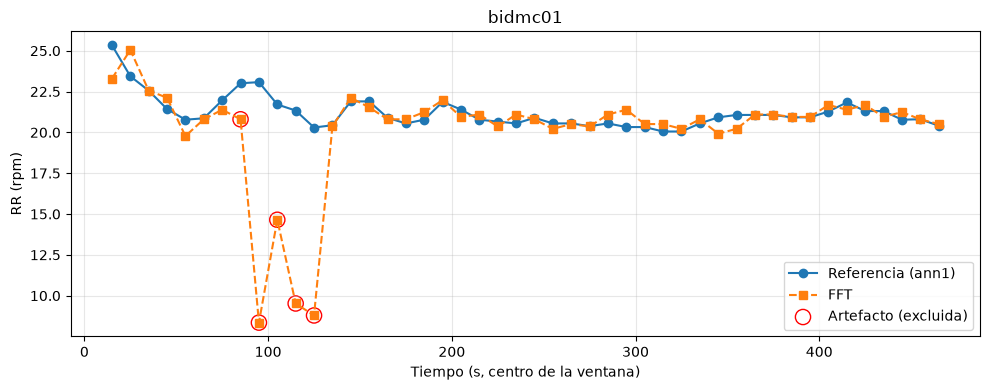

In [4]:
# v2-4 — Gráfico de un registro
p_graf = "bidmc01"
d = df_todos[df_todos["Paciente"] == p_graf]
tc = d["Inicio (s)"] + VENTANA_S / 2
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tc, d["RR referencia (rpm)"], "o-", label="Referencia (ann1)")
ax.plot(tc, d["RR FFT (rpm)"], "s--", label="FFT")
ax.scatter(tc[d["Artefacto"]], d.loc[d["Artefacto"], "RR FFT (rpm)"], s=120, facecolors="none",
           edgecolors="red", label="Artefacto (excluida)")
ax.set(xlabel="Tiempo (s, centro de la ventana)", ylabel="RR (rpm)", title=p_graf)
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()


In [5]:
# v2-5 — Ventanas para la red: las MISMAS filas de df_todos
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy.signal import decimate

FS_NET = 125                                # Hz: 30 s -> 3750 muestras (entrada de tu crear_modelo)
N_NET = VENTANA_S * FS_NET

def ventanas_red(paciente, inicios):
    rec = wfdb.rdrecord(str(BASE_DIR / "data" / paciente))
    nombres = [s.strip(" ,").upper() for s in rec.sig_name]
    x = rec.p_signal[:, nombres.index("PLETH")]
    if rec.fs != FS_NET:
        x = decimate(x, int(rec.fs // FS_NET), zero_phase=True)
    W = []
    for t0 in inicios:
        w = x[int(round(t0 * FS_NET)):int(round(t0 * FS_NET)) + N_NET]
        W.append((w - w.mean()) / (w.std() + 1e-6))     # z-score por ventana
    return np.stack(W).astype(np.float32)

assert df_todos.index.equals(pd.RangeIndex(len(df_todos))), "df_todos debe tener índice 0..n-1"
X = np.zeros((len(df_todos), N_NET), np.float32)
for p, d in df_todos.groupby("Paciente"):
    X[d.index] = ventanas_red(p, d["Inicio (s)"].to_numpy())
y = df_todos["RR referencia (rpm)"].to_numpy(np.float32)
print("X:", X.shape, " ventanas válidas para entrenar:", int(df_todos["Válida"].sum()))


X: (230, 3750)  ventanas válidas para entrenar: 199


In [7]:
# v2-6 — Modelo: tu arquitectura crear_modelo(), copiada sin cambios de 01_synthetic_ppg
def crear_modelo():
    model = keras.Sequential([
        layers.Input(shape=(3750, 1)),
        layers.Conv1D(16, 15, strides=3, padding="same",
                      activation="relu"),
        layers.MaxPooling1D(3),
        layers.Conv1D(32, 9, padding="same", activation="relu"),
        layers.MaxPooling1D(3),
        layers.LSTM(16),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="mse",
        metrics=["mae"]
    )
    return model

construir_modelo = crear_modelo


In [8]:
# v2-7 — Validación dejando un sujeto fuera (LOSO)
EPOCAS = 60
pacientes = sorted(df_todos["Paciente"].unique())
df_todos["RR CNN (rpm)"] = np.nan
df_todos["RR media train (rpm)"] = np.nan          # línea base trivial: predecir siempre la media

for k, p_test in enumerate(pacientes):
    resto = [p for p in pacientes if p != p_test]
    p_val = resto[k % len(resto)]                   # un sujeto de entrenamiento para early stopping
    tr = (df_todos["Paciente"].isin([p for p in resto if p != p_val]) & df_todos["Válida"]).to_numpy()
    va = ((df_todos["Paciente"] == p_val) & df_todos["Válida"]).to_numpy()
    te = (df_todos["Paciente"] == p_test).to_numpy()

    tf.keras.utils.set_random_seed(k)
    modelo = construir_modelo()
    modelo.fit(X[tr, :, None], y[tr] / 60, validation_data=(X[va, :, None], y[va] / 60),
               epochs=EPOCAS, batch_size=32, verbose=0,
               callbacks=[tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])
    df_todos.loc[te, "RR CNN (rpm)"] = modelo.predict(X[te, :, None], verbose=0).ravel() * 60
    df_todos.loc[te, "RR media train (rpm)"] = y[tr].mean()
    print(f"test={p_test}  val={p_val}  train={tr.sum()} val={va.sum()} test={te.sum()}")


test=bidmc01  val=bidmc02  train=112 val=46 test=46
test=bidmc02  val=bidmc03  train=117 val=36 test=46
test=bidmc03  val=bidmc04  train=122 val=41 test=46
test=bidmc04  val=bidmc05  train=123 val=35 test=46
test=bidmc05  val=bidmc01  train=123 val=41 test=46


In [9]:
# v2-8 — Comparación sobre las mismas ventanas válidas
metodos = {"FFT": "RR FFT (rpm)", "CNN-LSTM": "RR CNN (rpm)", "Media": "RR media train (rpm)"}
filas = []
for p, d in df_todos[df_todos["Válida"]].groupby("Paciente"):
    fila = {"Paciente": p, "n": len(d)}
    for nombre, col in metodos.items():
        fila[f"MAE {nombre}"] = (d[col] - d["RR referencia (rpm)"]).abs().mean()
    fila["Desv. pred. CNN"] = d["RR CNN (rpm)"].std()
    fila["Desv. referencia"] = d["RR referencia (rpm)"].std()
    filas.append(fila)
comparacion = pd.DataFrame(filas)
display(comparacion.round(2))
print("\nMediana MAE por sujeto:",
      {m: round(comparacion[f"MAE {m}"].median(), 2) for m in metodos})


,Paciente,n,MAE FFT,MAE CNN-LSTM,MAE Media,Desv. pred. CNN,Desv. referencia
0,bidmc01,41,0.40,3.85,7.49,1.06,0.96
1,bidmc02,46,0.54,2.16,0.51,2.64,0.59
2,bidmc03,36,1.13,1.22,3.21,0.46,0.53
3,bidmc04,41,0.74,3.25,1.65,2.12,0.83
4,bidmc05,35,0.56,14.35,10.10,5.55,0.55



Mediana MAE por sujeto: {'FFT': np.float64(0.56), 'CNN-LSTM': np.float64(3.25), 'Media': np.float64(3.21)}
